# Sportéo — ventes, marge et objectifs

**Simulation pédagogique sur données synthétiques.**

Comparer les magasins, les catégories et les années sans confondre chiffre d’affaires, marge commerciale et résultat net. Les CSV sources sont conservés ; aucun script JavaScript n’est utilisé.

In [1]:
from pathlib import Path
import os, sqlite3, textwrap
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

# Retrouver le dossier du projet depuis sa racine ou le dossier notebooks.
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / 'data/raw').is_dir())
RAW, CLEAN, OUT, REPORT = [ROOT / p for p in ['data/raw', 'data/processed', 'analysis', 'reports']]
for directory in [RAW, CLEAN, OUT, REPORT, ROOT / 'docs']:
    directory.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(20261010)
AUDIT, DICT, FIGS, SECTIONS = [], [], [], []
plt.rcParams.update({'figure.figsize': (10, 4.8), 'axes.spines.top': False, 'axes.spines.right': False})


In [2]:
def csv(df, file):
    df.to_csv(file, sep=";", index=False, encoding="utf-8-sig", float_format="%.8f")

def finish(title, question, metrics, tables, findings, actions, limits):
    """Exporter des résultats ouverts et préparer la restitution sans page web."""
    global METRICS, TITLE, QUESTION, FINDINGS, ACTIONS, LIMITS
    TITLE, QUESTION, METRICS = title, question, metrics
    FINDINGS, ACTIONS = findings, actions
    LIMITS = [s for s in limits if not any(w in s.lower() for w in ['natif', 'html', 'guide'])]
    csv(pd.DataFrame(AUDIT), OUT / 'qualite.csv')
    csv(pd.DataFrame(DICT), ROOT / 'docs/dictionnaire.csv')
    indicators = pd.DataFrame({'indicateur': metrics.keys(), 'valeur': list(metrics.values())})
    csv(indicators, OUT / 'indicateurs.csv')
    for name, table in tables.items():
        csv(table, OUT / (name + '.csv'))
    display(Markdown('## Résultats recalculés'))
    display(indicators)
    for item in findings:
        display(Markdown('- ' + item))
    from IPython.display import Image
    for name, fig in FIGS:
        display(Image(filename=str(REPORT / (name + '.png'))))
    plt.close('all')

class Restitution:
    """Relier les résultats calculés aux interprétations et aux recommandations."""
    def __init__(self):
        self.root = ROOT
        self.m = METRICS
        self.resume, self.actions = [], []
    def read(self, name):
        return pd.read_csv(ROOT / name, sep=';')
    def number(self, value, decimals=0):
        return f'{value:,.{decimals}f}'.replace(',', ' ').replace('.', ',')
    def pct(self, value, decimals=1):
        return self.number(value * 100, decimals) + ' %'
    def money(self, value, decimals=0):
        return self.number(value, decimals) + ' EUR'
    def section(self, title, paragraphs, tables=None):
        SECTIONS.append((title, paragraphs))
        display(Markdown('## ' + title + '\n\n' + '\n\n'.join(paragraphs)))
        for label, table in (tables or []):
            display(Markdown('### ' + label))
            display(table.head(30))


## Charger les sources et les référentiels

In [3]:
# Une ligne représente un produit d'une commande ; une commande peut avoir plusieurs lignes.
raw = pd.read_csv(RAW / 'ventes_brutes.csv', sep=';')
stores = pd.read_csv(CLEAN / 'magasins.csv', sep=';')
products = pd.read_csv(CLEAN / 'produits.csv', sep=';')
targets = pd.read_csv(CLEAN / 'objectifs.csv', sep=';')
display(raw.head())
assert stores.Magasin_ID.is_unique and products.Produit_ID.is_unique



  Ligne_ID Commande_ID        Date Magasin_ID Produit_ID Client_ID  \
0  L000001   CMD000001  2025-02-31         M8       P048    C10769   
1  L000002   CMD000001  2024-11-06         M8       P040    C10769   
2  L000003   CMD000002  2025-01-23         M8       P034    C10083   
3  L000004   CMD000002  2025-01-23         M8       P002    C10083   
4  L000005   CMD000003  2024-02-21         M8       P015    C01894   

             Canal  Quantite  Prix_unitaire  Remise_taux  Quantite_retournee  \
0          Magasin         3         122.20         0.16                   0   
1          Magasin         3          65.80         0.24                   0   
2  Click & Collect         3          25.90         0.16                   0   
3  Click & Collect         2          70.30         0.16                   0   
4          Magasin         3          92.95         0.06                   0   

   Cout_unitaire  
0          71.49  
1          36.85  
2          14.50  
3          32.34  
4  

## Isoler les doublons et les valeurs invalides

In [4]:
# Une date impossible n'est pas corrigée arbitrairement ; les exclusions restent consultables.
duplicates = raw.duplicated('Ligne_ID', keep='first')
unique = raw.loc[~duplicates].copy()
dates = pd.to_datetime(unique.Date, format='%Y-%m-%d', errors='coerce')
valid = (dates.notna() & unique.Quantite.gt(0) & unique.Quantite.eq(unique.Quantite.round())
         & unique.Produit_ID.isin(products.Produit_ID) & unique.Magasin_ID.isin(stores.Magasin_ID)
         & unique.Remise_taux.between(0, 1) & unique.Quantite_retournee.between(0, unique.Quantite))
sales = unique.loc[valid].copy()
rejected = unique.loc[~valid].copy()
rejected['Motif'] = 'Date, quantité, référentiel, retour ou remise invalide : voir les règles ci-dessus.'
csv(raw.loc[duplicates], OUT / 'doublons.csv')
csv(rejected, OUT / 'rejets.csv')
AUDIT.append({'table': 'ventes', 'brut': len(raw), 'doublons': int(duplicates.sum()), 'rejets': len(rejected), 'propre': len(sales)})
assert len(raw) == duplicates.sum() + len(rejected) + len(sales)
assert sales.Ligne_ID.is_unique
display(pd.DataFrame(AUDIT))



    table   brut  doublons  rejets  propre
0  ventes  60240       240     120   59880

## Calculer les montants au centime et contrôler les jointures

In [5]:
# Les calculs en centimes appliquent un arrondi commercial explicite à la vente et au remboursement.
price_cents = np.rint(sales.Prix_unitaire * 100).astype('int64')
cost_cents = np.rint(sales.Cout_unitaire * 100).astype('int64')
discount_percent = np.rint(sales.Remise_taux * 100).astype('int64')
invoiced = (sales.Quantite * price_cents * (100 - discount_percent) + 50) // 100
refunded = (sales.Quantite_retournee * price_cents * (100 - discount_percent) + 50) // 100
cost = (sales.Quantite - sales.Quantite_retournee) * cost_cents
sales['CA_facture'], sales['Remboursements'] = invoiced / 100, refunded / 100
sales['CA_net'], sales['Cout_net'] = (invoiced - refunded) / 100, cost / 100
sales['Marge_nette'] = (invoiced - refunded - cost) / 100
sales = sales.merge(products[['Produit_ID', 'Categorie']], on='Produit_ID', validate='many_to_one').merge(stores[['Magasin_ID', 'Magasin']], on='Magasin_ID', validate='many_to_one')
sales['Annee'], sales['Mois'] = sales.Date.str[:4], sales.Date.str[:7]
assert len(sales) == AUDIT[0]['propre']
assert np.isclose(sales.CA_net.sum(), sales.CA_facture.sum() - sales.Remboursements.sum())
csv(sales, CLEAN / 'ventes.csv')



## Comparer les périodes et les contributions

In [6]:
# Les taux sont des rapports de sommes ; les commandes sont comptées distinctement dans chaque périmètre.
def aggregate(frame, keys):
    table = frame.groupby(keys).agg(CA_net=('CA_net', 'sum'), Marge_nette=('Marge_nette', 'sum'), Remboursements=('Remboursements', 'sum'), Quantite=('Quantite', 'sum'), Retours=('Quantite_retournee', 'sum'), Commandes=('Commande_ID', 'nunique')).reset_index()
    table['Taux_marque'] = table.Marge_nette / table.CA_net
    table['Taux_retour'] = table.Retours / table.Quantite
    table['Panier_net'] = table.CA_net / table.Commandes
    return table

annual = aggregate(sales, 'Annee')
monthly = aggregate(sales, 'Mois')
by_store = aggregate(sales, 'Magasin')
categories = aggregate(sales, 'Categorie')
store_year = aggregate(sales, ['Magasin', 'Annee'])
for table in [annual, monthly, by_store, categories]:
    assert np.isclose(table.CA_net.sum(), sales.CA_net.sum())
display(annual)
display(store_year)



  Annee      CA_net  Marge_nette  Remboursements  Quantite  Retours  \
0  2024  5400041.74   2232984.66        92049.84     60342      998   
1  2025  5236843.47   2123363.04       103597.65     59718     1173   

   Commandes  Taux_marque  Taux_retour  Panier_net  
0      15065     0.413512     0.016539  358.449501  
1      14935     0.405466     0.019642  350.642348  

        Magasin Annee     CA_net  Marge_nette  Remboursements  Quantite  \
0      Bordeaux  2024  691158.64    288887.52         9662.75      7678   
1      Bordeaux  2025  671575.79    280530.27        12037.99      7581   
2         Lille  2024  647779.01    251770.27        12797.49      7584   
3         Lille  2025  639714.86    249140.30        11083.72      7529   
4          Lyon  2024  659896.85    276210.97        10331.42      7419   
5          Lyon  2025  582357.11    198898.52        29643.20      7517   
6   Montpellier  2024  700543.86    291630.95        11525.97      7785   
7   Montpellier  2025  674047.15    282052.57        11091.67      7371   
8        Nantes  2024  666962.64    276720.49        11951.26      7349   
9        Nantes  2025  671474.37    279921.17         8653.54      7351   
10       Rennes  2024  664268.44    277649.49        12782.31      7419   
11       Rennes  2025  680417.59    283077.49        11121.45      7633   
12   Strasbourg  2024  68

## Confronter les ventes aux objectifs au bon grain

In [7]:
# Un objectif par mois et magasin est joint aux ventes agrégées, jamais à chaque ligne de vente.
actual = aggregate(sales, ['Magasin_ID', 'Mois'])
targets['Mois'] = targets.Date.str[:7]
assert not targets.duplicated(['Magasin_ID', 'Mois']).any()
objectives = targets.merge(actual, on=['Magasin_ID', 'Mois'], how='left', validate='one_to_one')
assert objectives.CA_net.notna().all()
objectives['Atteinte_CA'] = objectives.CA_net / objectives.Objectif_CA
objectives['Ecart_CA'] = objectives.CA_net - objectives.Objectif_CA
objectives['Atteint'] = objectives.CA_net.ge(objectives.Objectif_CA)
display(objectives.head(12))



          Date Magasin_ID  Objectif_CA  Objectif_taux_marque     Mois  \
0   2024-01-01         M1        72800                  0.37  2024-01   
1   2024-01-01         M2        75600                  0.37  2024-01   
2   2024-01-01         M3        78400                  0.37  2024-01   
3   2024-01-01         M4        81200                  0.37  2024-01   
4   2024-01-01         M5        84000                  0.37  2024-01   
5   2024-01-01         M6        86800                  0.37  2024-01   
6   2024-01-01         M7        89600                  0.37  2024-01   
7   2024-01-01         M8        92400                  0.37  2024-01   
8   2024-02-01         M1        65000                  0.37  2024-02   
9   2024-02-01         M2        67500                  0.37  2024-02   
10  2024-02-01         M3        70000                  0.37  2024-02   
11  2024-02-01         M4        72500                  0.37  2024-02   

      CA_net  Marge_nette  Remboursements  Quantit

## Visualiser et formuler les décisions avec leurs limites

## Résultats recalculés

             indicateur        valeur
0        lignes_valides  5.988000e+04
1                ca_net  1.063689e+07
2     marge_commerciale  4.356348e+06
3           taux_marque  4.095511e-01
4  commandes_distinctes  3.000000e+04
5     evolution_ca_2025 -3.022167e-02
6    atteinte_objectifs  7.012626e-01
7    objectifs_atteints  0.000000e+00

- CA net : 10,636,885.21 EUR ; marge commerciale : 4,356,347.70 EUR.

- Évolution 2025 / 2024 : -3.0% ; atteinte globale des objectifs : 70.1%.

- 0 couples mois-magasin atteignent leur objectif sur 192.

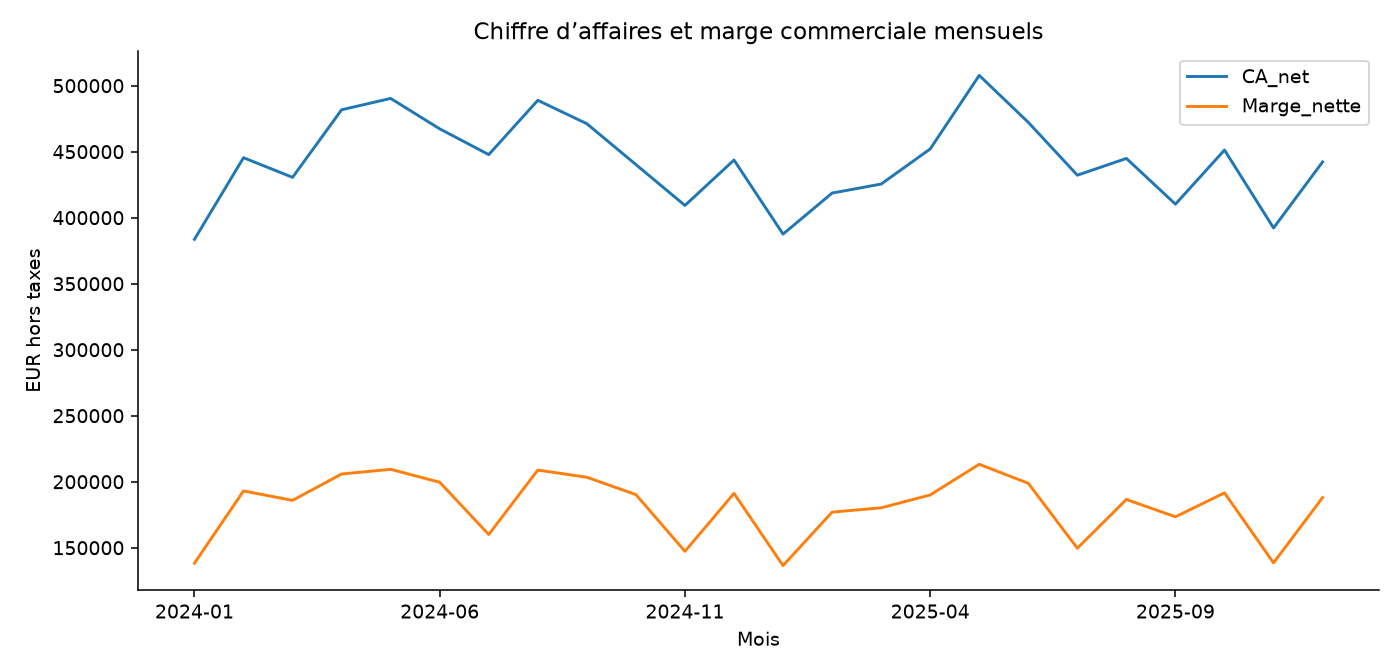

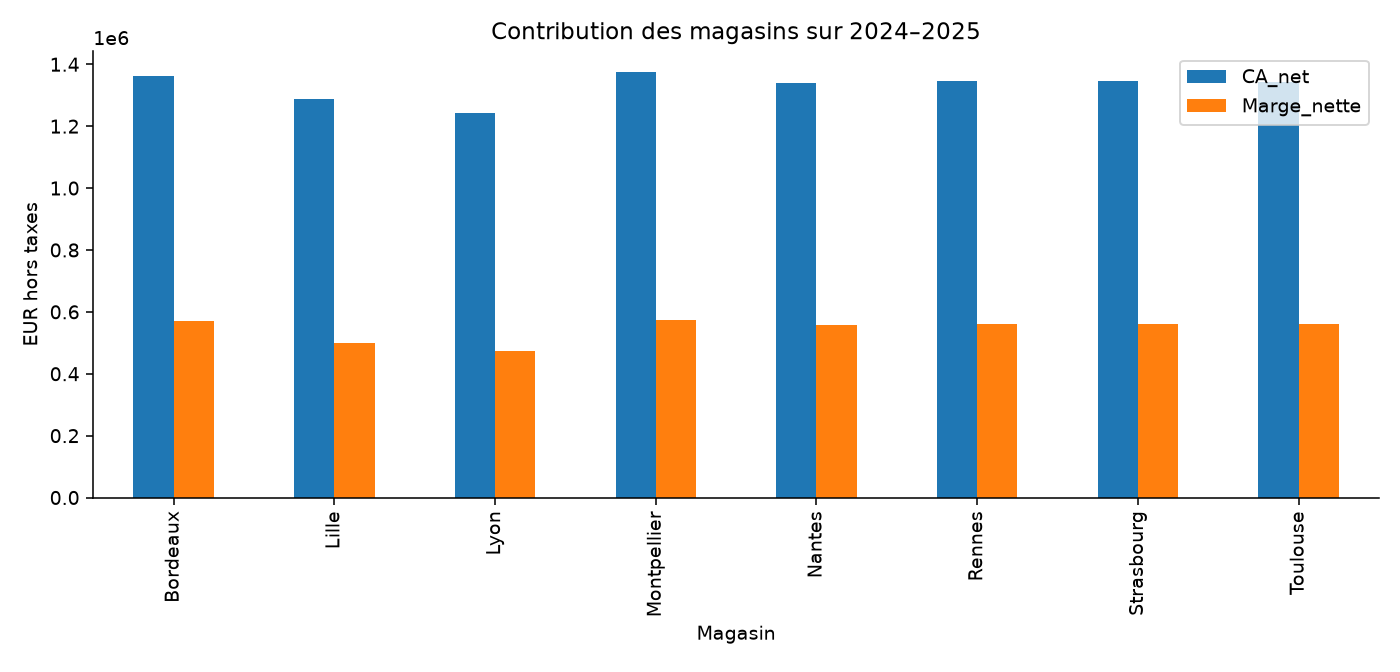

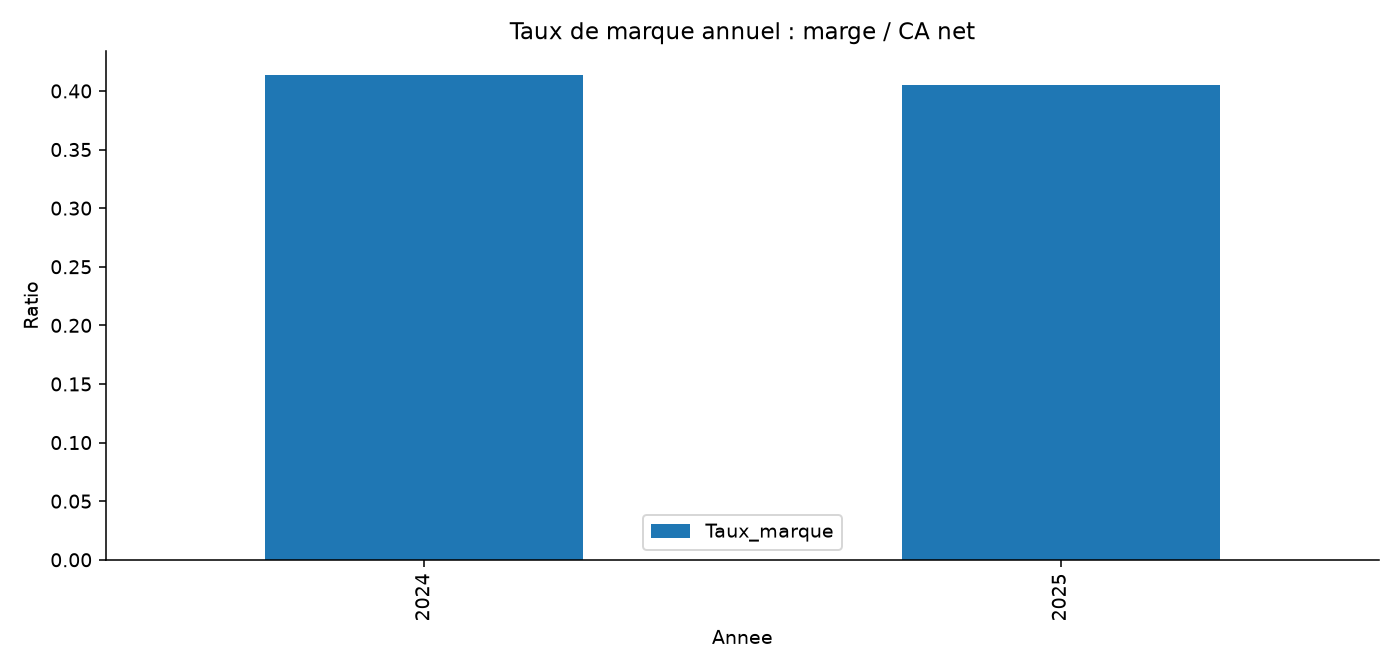

In [8]:
for name, frame, x, columns, title in [
    ('ventes_mensuelles', monthly, 'Mois', ['CA_net', 'Marge_nette'], 'Chiffre d’affaires et marge commerciale mensuels'),
    ('contribution_magasins', by_store, 'Magasin', ['CA_net', 'Marge_nette'], 'Contribution des magasins sur 2024–2025'),
    ('taux_marque_annuel', annual, 'Annee', ['Taux_marque'], 'Taux de marque annuel : marge / CA net')]:
    fig, ax = plt.subplots(figsize=(10, 4.8))
    frame.plot(x=x, y=columns, kind='bar' if x != 'Mois' else 'line', ax=ax)
    ax.set_title(title)
    ax.set_ylabel('Ratio' if 'taux' in name else 'EUR hors taxes')
    fig.tight_layout()
    fig.savefig(REPORT / (name + '.png'), dpi=140)
    FIGS.append((name, fig))
growth = annual.iloc[1].CA_net / annual.iloc[0].CA_net - 1
metrics = {'lignes_valides': len(sales), 'ca_net': sales.CA_net.sum(), 'marge_commerciale': sales.Marge_nette.sum(), 'taux_marque': sales.Marge_nette.sum() / sales.CA_net.sum(), 'commandes_distinctes': sales.Commande_ID.nunique(), 'evolution_ca_2025': growth, 'atteinte_objectifs': sales.CA_net.sum() / targets.Objectif_CA.sum(), 'objectifs_atteints': int(objectives.Atteint.sum())}
finish('Sportéo — performance commerciale', 'Quels magasins et catégories contribuent au CA et à la marge, et quels écarts aux objectifs faut-il investiguer ?', metrics,
       {'annuel': annual, 'mensuel': monthly, 'magasins': by_store, 'categories': categories, 'magasins_annees': store_year, 'objectifs': objectives},
       [f"CA net : {metrics['ca_net']:,.2f} EUR ; marge commerciale : {metrics['marge_commerciale']:,.2f} EUR.", f"Évolution 2025 / 2024 : {growth:.1%} ; atteinte globale des objectifs : {metrics['atteinte_objectifs']:.1%}.", f"{metrics['objectifs_atteints']} couples mois-magasin atteignent leur objectif sur {len(objectives)}."],
       ['Examiner les remises et retours par magasin avant toute recommandation.', 'Réviser les objectifs simulés et leur saisonnalité avec les responsables métier.', 'Suivre la marge et le CA ensemble, avec des dénominateurs cohérents.'],
       ['Données entièrement fictives, sans mission client réelle.', 'La marge commerciale exclut les charges fixes, impôts et coûts logistiques.', 'Retours imputés au mois de vente et supposés remis en stock.', 'Les différences descriptives ne prouvent aucune causalité.'])


## Rapport principal Excel et Power Query

Le classeur `excel/Sporteo_Analyse.xlsx` est le livrable principal. Ce notebook sert de vérification indépendante des calculs ; il ne régénère pas le rapport PowerPoint pour préserver la présentation Excel/Power Query.